# Prueba Intertrimestral

**Nombre:** Hugo 
**Apellidos:** Raggini Paternain 

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [31]:

import pandas as pd
import numpy as np

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [32]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type == "classic":
        base_fee = 1.00
        cost_per_minute = 0.05
    elif bike_type == "electric":
        base_fee = 1.50
        cost_per_minute = 0.08
    else:
        raise ValueError

    total_cost = base_fee + (cost_per_minute*duration_min)

    if is_member:
        total_cost =total_cost*0.80

    return round(total_cost, 3)

ejemplo_tar = rental_fee(23, "classic", False)
print({ejemplo_tar})

{2.15}


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [33]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif threshold/2 <= total_rentals < threshold:
        return "Media"
    else:
        return "Baja"

ejemplo_et = demand_label(200, 100)
print({ejemplo_et})

{'Alta'}


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [34]:
N = 10

duration_mins = np.random.uniform(10, 120, N)
bike_types = np.random.choice(["classic", "electric"], N)
is_members = np.random.choice([True, False], N)
total_rentals_arr = np.random.randint(10, 100, N)

tripsDemo = pd.DataFrame({
    "duration_min": duration_mins,
    "bike_type": bike_types,
    "is_member": is_members,
    "fee": [rental_fee(d, b, m) for d, b, m in zip(duration_mins, bike_types, is_members)],
    "total_rentals": total_rentals_arr,
    "demand": [demand_label(r, threshold=40) for r in total_rentals_arr]
})

display(tripsDemo)

,duration_min,bike_type,is_member,fee,total_rentals,demand
0,22.580132,classic,True,1.703,84,Alta
1,26.315104,electric,False,3.605,88,Alta
2,24.354195,classic,True,1.774,98,Alta
3,84.481748,electric,True,6.607,58,Alta
4,103.168573,classic,True,4.927,81,Alta
5,45.383524,electric,True,4.105,85,Alta
6,24.222895,electric,False,3.438,84,Alta
7,45.383180,classic,True,2.615,42,Alta
8,44.420471,electric,False,5.054,45,Alta
9,32.029431,classic,True,2.081,33,Media


\d) (0.2 pts) Integra ambas funciones en una clase

1.   Elemento de lista
2.   Elemento de lista

`MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [38]:
mobilityData=pd.read_csv("city_micromobility_hourly.csv")
display(mobilityData.head(5))
print(mobilityData.shape)

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


(17520, 23)


*b*) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [42]:
def describeData(dataFrame):
    summary_df = pd.DataFrame({
        'tipo_dato': dataFrame.dtypes,
        'nulos':dataFrame.isnull().sum(),
        'porcentaje_nulos': (dataFrame.isnull().sum()/len(dataFrame))*100
    })
    return summary_df



c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [45]:
display(describeData(mobilityData))

#Los valores que mas nulos tienen son humidity (1.27%), wind_kmh (0.81%), avg_trip_min(1.45%) y electric_share (1.04%).
#Los cuatro son numeros float. Antes de modelar habría que tratarlos, lo mas sencillo es completar con ceros.


,tipo_dato,nulos,porcentaje_nulos
datetime,object,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,object,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [49]:
targetVar = "total_rentals"
predictor_vars = ["hour", "temp_c", "humidity", "wind_kmh", "precip_mm", "is_workingday", "is_weekend"]

data_clean = mobilityData[[targetVar] + predictor_vars].dropna()

X = data_clean[predictor_vars]
y = data_clean[targetVar]

print(f"Variable Objetivo (y): {targetVar}")
print(f"Variables Predictoras (X): {predictor_vars}")

Variable Objetivo (y): total_rentals
Variables Predictoras (X): ['hour', 'temp_c', 'humidity', 'wind_kmh', 'precip_mm', 'is_workingday', 'is_weekend']


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [51]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.3, # 30% para prueba
        random_state=42 # Semilla para reproducibilidad
    )


print(f"Conjunto original (X_new): {X.shape[0]} registros.")
print("\nDimensiones de los conjuntos:")
print(f"X_train (70%): {X_train.shape}")
print(f"X_test (30%): {X_test.shape}")
print(f"y_train (70%): {y_train.shape}")
print(f"y_test (30%): {y_test.shape}")

Conjunto original (X_new): 17159 registros.

Dimensiones de los conjuntos:
X_train (70%): (12011, 7)
X_test (30%): (5148, 7)
y_train (70%): (12011,)
y_test (30%): (5148,)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [56]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error


lm = LinearRegression()

lm.fit(X_train, y_train)

y_pred = lm.predict(X_test)

# Calcular el R² (Coeficiente de Determinación)
r2 = r2_score(y_test, y_pred)

# Calcular el MSE (Mean Squared Error)
mse = mean_squared_error(y_test, y_pred)

mse_porcentaje=mse/y_test.mean()
mse_porcentaje=mse/y_test.max()


print("--- Evaluación del Nuevo Modelo de Regresión Lineal (sin Peso ni Altura) ---")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print(f"MSE (Error Cuadrático Medio): {mse:.4f}")
print (mse_porcentaje)

# Coeficiente de determinacion bajo (0.3) - esto quiere decir que entre la variable independiente tiene poca correlacion con las variables dependientes, no son las mejores predictoras de esta.
# Aplicado a este ejemplo lo que sucede es que las variables: hour, temp_c, humidity, wind_kmh, precip_mm, is_workingday, is_weekend no son buenas predictoras de total_rentals
# MSE en valores absolutos me cuesta leerlo - pero si vemos los valores relativos vemos que sobre la media (c.10%) es una desviacion notable frente a que sobre el max es c.3.49%.

--- Evaluación del Nuevo Modelo de Regresión Lineal (sin Peso ni Altura) ---
R² (Coeficiente de Determinación): 0.3014
MSE (Error Cuadrático Medio): 412.5941
3.4965604312680503


d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [58]:
from sklearn.ensemble import RandomForestRegressor


rf = RandomForestRegressor(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

# Calcular el R²
r2_rf = r2_score(y_test, y_pred)

# Calcular el MSE
mse_rf = mean_squared_error(y_test, y_pred_rf)

print("--- Evaluación del Modelo Random Forest Regressor ---")
print(f"R² (Random Forest): {r2_rf:.4f}")
print(f"MSE (Random Forest): {mse_rf:.4f}")

print("\n--- Comparación de Rendimiento (usando las mismas 4 variables indirectas) ---")
print(f"| Modelo                | R²         | MSE       |")
print(f"|-----------------------|------------|-----------|")
print(f"| Regresión Lineal      | {r2:.4f}   | {mse:.4f}  |")
print(f"| Random Forest         | {r2_rf:.4f}| {mse_rf:.4f}  |")

# Determinar qué modelo tiene mejor rendimiento
if r2_rf > r2:
    mejor_modelo = "Random Forest"
elif r2 > r2_rf:
    mejor_modelo = "Regresión Lineal"
else:
    mejor_modelo = "Ambos modelos tienen un rendimiento similar."


#ambos tienen un rendimiento similar, no obstante, Random Forest tiene un menor MSE, por si solo valoramos estas dos metricas, tiene sentido elegir el Random Forest. Este tambien es mas costoso.



--- Evaluación del Modelo Random Forest Regressor ---
R² (Random Forest): 0.3014
MSE (Random Forest): 64.0936

--- Comparación de Rendimiento (usando las mismas 4 variables indirectas) ---
| Modelo                | R²         | MSE       |
|-----------------------|------------|-----------|
| Regresión Lineal      | 0.3014   | 412.5941  |
| Random Forest         | 0.3014| 64.0936  |


## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.1


In [65]:
print(mobilityData['high_demand'].value_counts()/len(mobilityData))


high_demand
0    0.688984
1    0.311016
Name: count, dtype: float64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

predictor_vars_class = [
    'hour',
    'temp_c',
    'humidity',
    'wind_kmh',
    'precip_mm',
    'is_workingday',
    'is_weekend'
]
target_var_class = 'high_demand'

data_class = mobilityData[[target_var_class] + predictor_vars_class].dropna()

X_class = data_class[predictor_vars_class]
y_class = data_class[target_var_class]

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.3,
    random_state=42,
    stratify=y_class
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_class)
X_test_scaled = scaler.transform(X_test_class)

logistic_model = LogisticRegression(random_state=42, solver='liblinear')
logistic_model.fit(X_train_scaled, y_train_class)

print("Modelo de Regresión Logística entrenado exitosamente para predecir 'high_demand'.")
print(f"Dimensiones de entrenamiento (X): {X_train_scaled.shape}")
print(f"Número de características usadas: {len(predictor_vars_class)}")

Modelo de Regresión Logística entrenado exitosamente para predecir 'high_demand'.
Dimensiones de entrenamiento (X): (12011, 7)
Número de características usadas: 7


c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Exactitud (Accuracy) del modelo de Regresión Logística: 0.7537 (75.37%)

Matriz de Confusión (Numérica):
[[3222  324]
 [ 944  658]]


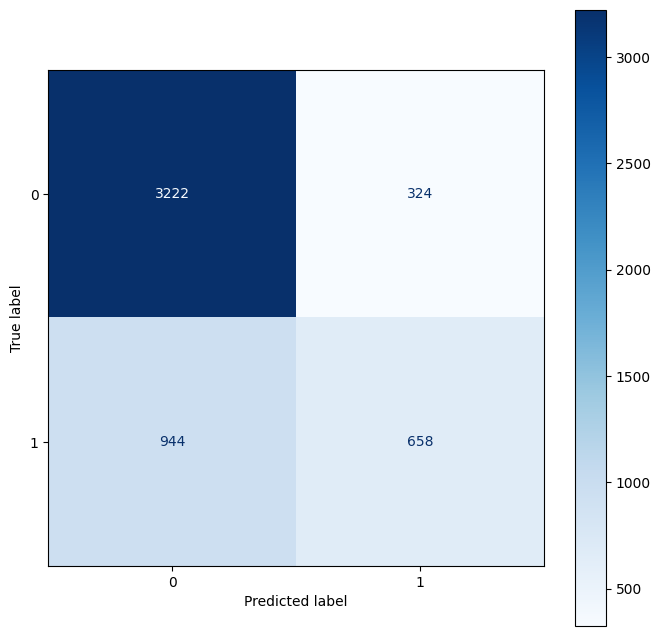

In [73]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_class = logistic_model.predict(X_test_scaled)

accuracy_class = accuracy_score(y_test_class, y_pred_class)

print(f"Exactitud (Accuracy) del modelo de Regresión Logística: {accuracy_class:.4f} ({(accuracy_class*100):.2f}%)")

cm_class = confusion_matrix(y_test_class, y_pred_class)

print("\nMatriz de Confusión (Numérica):")
print(cm_class)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_class, display_labels=[0, 1])

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [71]:
coefficients = logistic_model.coef_[0]

predictor_vars_class = X_class.columns

feature_importance = pd.DataFrame({
    'Feature': predictor_vars_class,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

print("Importancia de las Variables (Coeficientes de Regresión Logística Estandarizados):")
print(feature_importance)


# La importancai de las variables dependites respecto a la independiente se mide en como de grande es el valor absoluto del coeficiente.
# En este caso las mas importantes con diferencia son precip_mm y temp_c
# esto tiene sentido si se piensa ya que a) precip_mm (coef negativo), quiere decir que cuanto menos llueve mas demanda de movilidad y b) a mayor temperature, mayor demanda de micromovilidad. En efecto, el buen tiempo motiva el movimiento en bicicleta.
#

Importancia de las Variables (Coeficientes de Regresión Logística Estandarizados):
         Feature  Coefficient  Abs_Coefficient
4      precip_mm    -0.818665         0.818665
1         temp_c     0.756401         0.756401
0           hour     0.378172         0.378172
6     is_weekend     0.316818         0.316818
2       humidity    -0.245270         0.245270
3       wind_kmh    -0.146548         0.146548
5  is_workingday     0.070138         0.070138


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y po\r qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



In [ ]:
# 1) Como se ha mencionado en el apartado anterior, los factores que mas mueven la demanda de micromovilidad son el precip_mm (invesrsamente, es decir, que cuanto menos llueva, mas demanda) y temp_c (directamente, es decir, a mayor tempertaura, mayor demanda)
# 2) El modelo que ha funcioando mejor ha sido el de regresion logistica - dentro de la estrategia de clasificacion. Se ve que a efectos de calcular que mueve la mayor demanda, cuadra y tiene mas sentido hacelro en base a la variable de high_demand que de total_rentals. Total rentals, es una variable que da mas informacion porque al fin y al cabo es una variable que depende del total rentals como bien dice su descripcion: se aciva en el tercio mas alto de su demanda historica.
# 3) Sabiendo que mueve la demanda, seria inetresante intentar relacionar esto con el total_rentals - una variable cuyo contenido mas substancioso que high demand.